In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
from IPython.display import Markdown, Image, display
P = ROOT / "data" / "processed"
F = ROOT / "docs" / "figures"
pd.options.display.float_format = "{:,.4f}".format
def table(name): return pd.read_csv(P / name)
def summary(name): return json.loads((P / name).read_text())
def fig(name): display(Image(filename=str(F / name)))
print("Simulated data. Every number below is read from executed pipeline outputs.")


Simulated data. Every number below is read from executed pipeline outputs.


# M4. Elasticity, scenarios and endogeneity bias (Simulated data)

## Why observational elasticities are biased

In the observational data our price depends on the unobserved intent $u$:

$$\ln P_i = \ln P^{\text{tech}}_i + \gamma u_i + \varepsilon_i, \qquad \operatorname{logit} \Pr(\text{convert}_i) = \alpha + \beta \ln r_i + \theta u_i + \dots$$

where $r_i$ is our price relative to the market. Customers with high $u$ are both charged more and more likely to buy. A model that cannot see $u$ attributes part of $\theta u$ to the price term, so the estimated $\hat\beta$ is pulled towards zero (attenuated). The elasticity is then too small in magnitude and a price rise looks cheaper than it is.

A randomised price test breaks the link between price and $u$, so the experimental estimate is unbiased up to sampling error. The numbers below come from executed code.

In [2]:
s = summary("m4_summary.json")
e = s["endogeneity"]
display(Markdown(f"""
- Correlation of log price ratio with latent intent: **{e['corr_ln_ratio_intent']:.3f}**
- Regression slope of intent on log price ratio: **{e['slope_intent_on_ln_ratio']:.3f}**
- Oracle GLM that includes intent: intent coefficient **{e['oracle_intent_coefficient']:.3f}** versus true **{e['true_intent_coefficient']:.3f}**
- Overall elasticity: truth **{s['elasticity_overall']['true']:.2f}**, GLM on observational data **{s['elasticity_overall']['glm_observational']:.2f}**, GBM **{s['elasticity_overall']['gbm_observational']:.2f}**, randomised test **{s['elasticity_overall']['experiment']:.2f}** (95% CI {s['elasticity_overall']['ci_low']:.2f} to {s['elasticity_overall']['ci_high']:.2f}), GLM with intent added **{s['elasticity_overall']['glm_with_latent_intent']:.2f}**
"""))


- Correlation of log price ratio with latent intent: **0.279**
- Regression slope of intent on log price ratio: **3.202**
- Oracle GLM that includes intent: intent coefficient **0.600** versus true **0.600**
- Overall elasticity: truth **-6.03**, GLM on observational data **-3.70**, GBM **-4.05**, randomised test **-5.75** (95% CI -7.07 to -4.30), GLM with intent added **-5.83**


In [3]:
table("m4_elasticity_comparison__simulated_data.csv")

,group,quotes,true,glm_observational,gbm_observational,experiment,ci_low,ci_high,true_on_test_rows,bias_glm_observational,bias_gbm_observational,bias_experiment,glm_with_latent_intent
0,overall,20512,-6.0314,-3.7026,-4.0502,-5.7527,-7.0656,-4.3027,-6.2205,2.3288,1.9812,0.2787,-5.8265
1,channel:PCW,13898,-9.2282,-6.9006,-6.7269,-9.1995,-11.1870,-7.3288,-9.3658,2.3276,2.5013,0.0287,-9.1035
2,channel:direct,4615,-3.5678,-1.4640,-1.6773,-3.8761,-6.3350,-1.8268,-3.4884,2.1038,1.8905,-0.3083,-3.5192
3,channel:broker,1999,-2.3670,0.5828,-1.4710,1.1687,-2.1073,4.4553,-2.3055,2.9499,0.8961,3.5357,-1.4897
4,age:17-24,1670,-6.3258,-5.3645,-5.1947,-4.4546,-11.7284,3.3106,-6.9611,0.9614,1.1311,1.8712,NaN
5,age:25-34,4525,-6.8169,-4.4689,-4.2030,-6.2044,-8.9755,-3.4093,-6.8547,2.3480,2.6140,0.6125,NaN
6,age:35-49,6291,-6.0329,-3.4316,-3.8220,-4.6066,-6.6979,-1.9451,-6.2177,2.6013,2.2109,1.4263,NaN
7,age:50-64,4998,-5.8856,-3.7874,-4.2647,-5.7432,-7.7492,-3.6818,-6.2362,2.0982,1.6210,0.1424,NaN
8,age:65+,3028,-4.9461,-2.3064,-3.4203,-7.9868,-11.6409,-4.3835,-4.9014,2.6398,1.5258,-3.0407,NaN


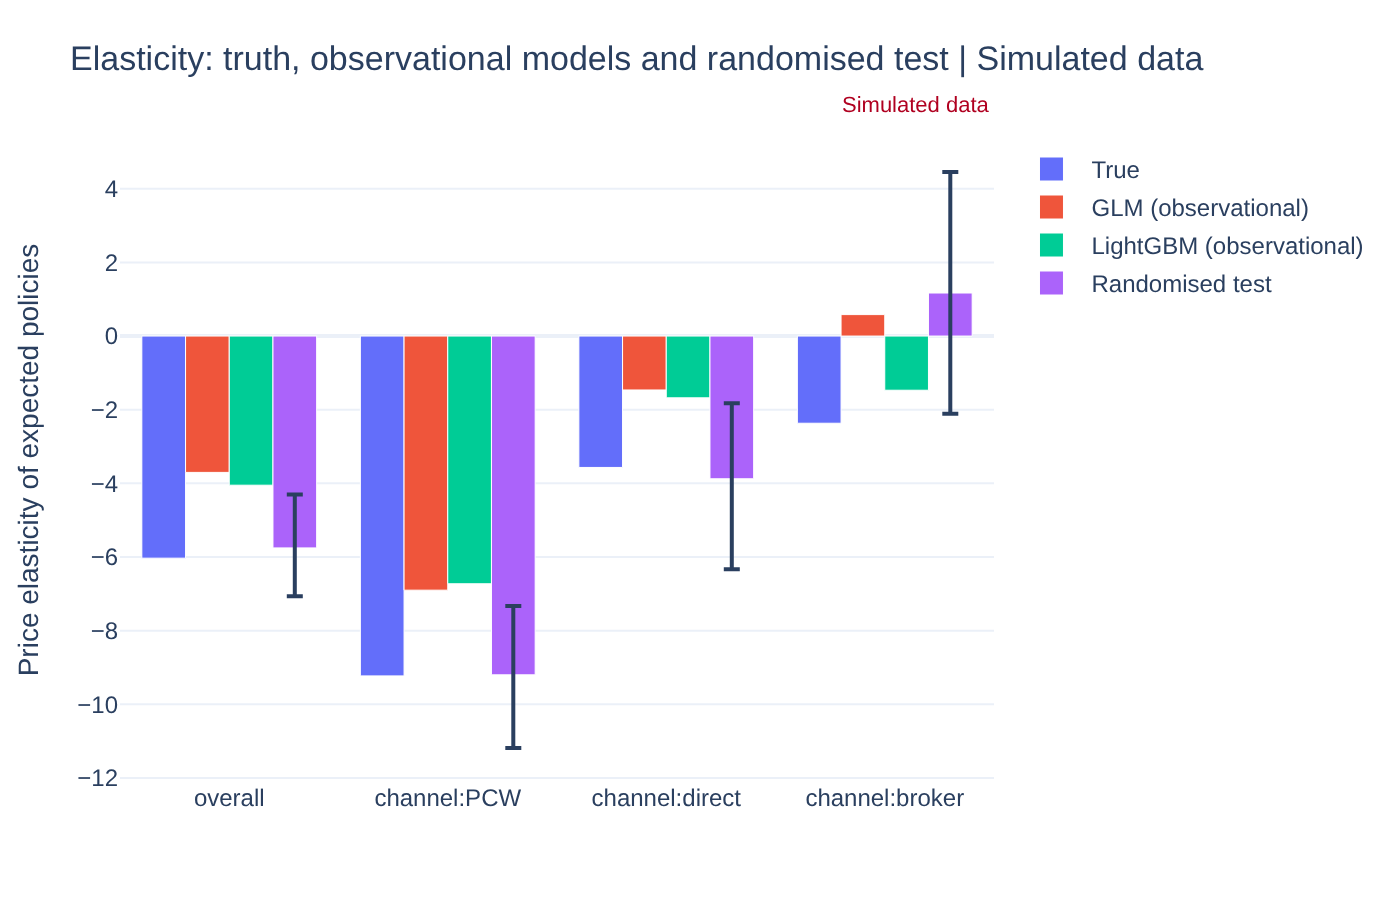

In [4]:
fig("m4_elasticity_comparison__simulated_data.png")

## Reading the broker row
The broker experimental estimate has a wide interval that spans zero (see table above). Broker volume in the test is small. The calibration therefore pools direct and broker to the off-PCW experimental estimate. This is a limitation of the experiment size, not a finding about brokers.

In [5]:
table("m4_experiment_arms__simulated_data.csv")

,treatment_group,quotes,conversion,mean_price_change,arc_elasticity_vs_control
0,T-5,3642,0.1282,-0.0500,-6.6154
1,T-2,3650,0.1000,-0.0200,-4.4894
2,control,6274,0.0913,0.0000,NaN
3,T+2,3600,0.0781,0.0200,-7.9308
4,T+5,3739,0.0749,0.0500,-4.0684


## Scenarios
Portfolio price changes of -5, -2, 0, +2 and +5%, using the experiment-calibrated GLM with rank recomputed from competitor prices.

In [6]:
table("m4_scenarios__simulated_data.csv")

,price_change,conversion_probability,expected_policies,gwp,average_premium,contribution,margin,source
0,-0.0500,0.1113,"2,282.7235","1,335,273.3135",584.9475,"85,744.8414",0.0642,true
1,-0.0200,0.0912,"1,870.1067","1,129,067.3482",603.7449,"108,528.8752",0.0961,true
2,0.0000,0.0805,"1,650.8795","1,017,319.5771",616.2288,"118,247.0768",0.1162,true
3,0.0200,0.0715,"1,466.9643","922,750.6364",629.0205,"125,219.7108",0.1357,true
4,0.0500,0.0606,"1,243.4645","806,310.4939",648.4387,"131,744.5029",0.1634,true
5,-0.0500,0.1002,"2,056.2075","1,202,356.7339",584.7448,"74,790.4126",0.0622,glm_observational
6,-0.0200,0.0879,"1,802.9887","1,086,990.5132",602.8826,"102,165.6445",0.0940,glm_observational
7,0.0000,0.0813,"1,668.2800","1,025,876.1687",614.9305,"117,012.0835",0.1141,glm_observational
8,0.0200,0.0757,"1,553.2786","974,291.7202",627.2485,"130,050.1101",0.1335,glm_observational
9,0.0500,0.0689,"1,413.5920","912,756.4364",645.7001,"146,935.6109",0.1610,glm_observational


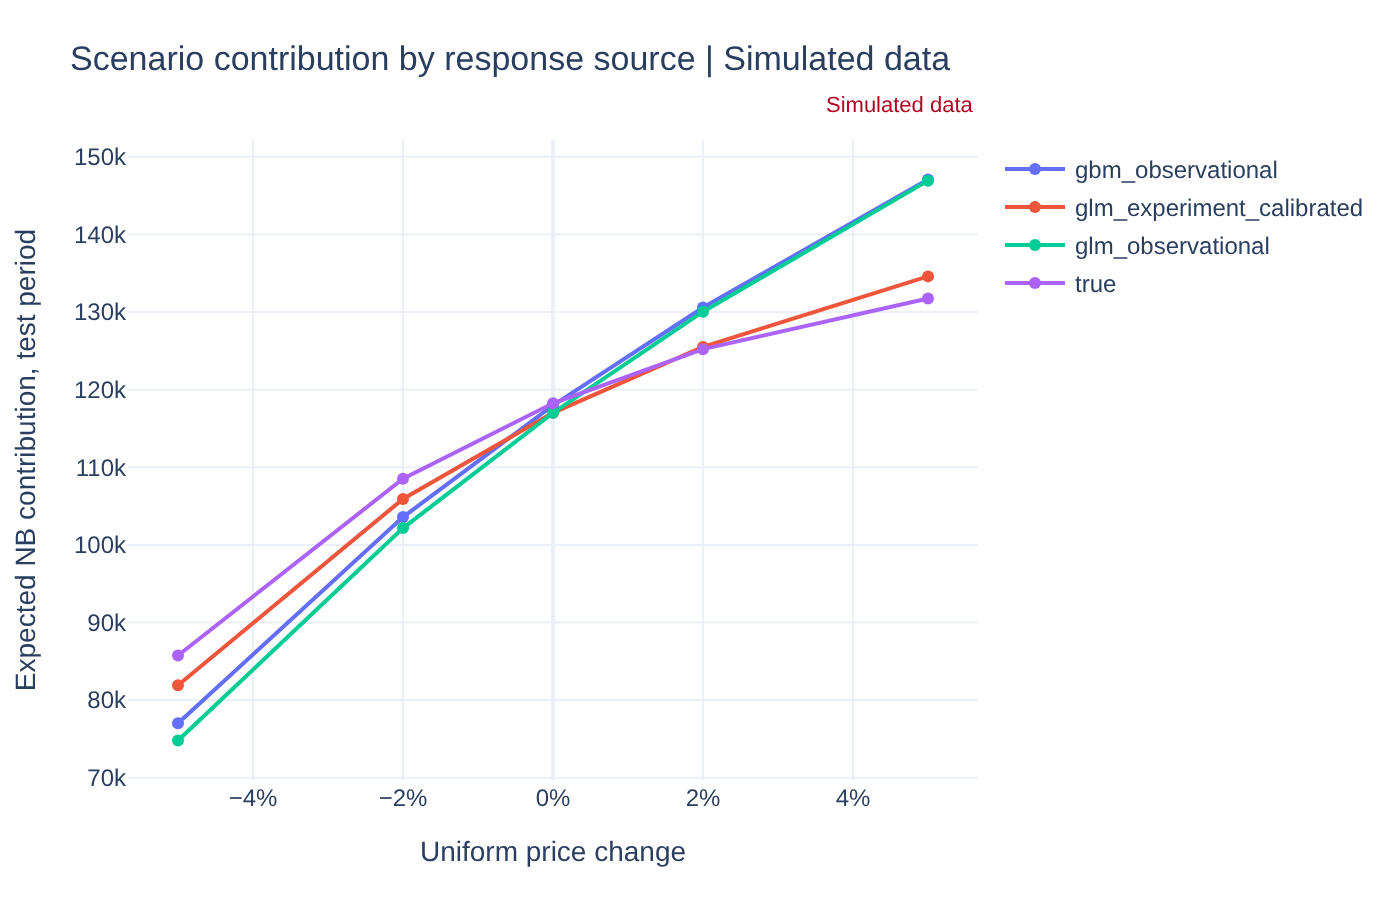

In [7]:
fig("m4_scenario_contribution__simulated_data.png")

## Sensitivities

In [8]:
display(table("m4_sensitivity_elasticity_multiplier__simulated_data.csv"))
display(table("m4_sensitivity_cost__simulated_data.csv"))
table("m4_sensitivity_step__simulated_data.csv")

,price_change,conversion_probability,expected_policies,gwp,average_premium,contribution,margin,elasticity_multiplier
0,-0.0200,0.0858,"1,759.8567","1,060,882.0474",602.8230,"100,380.5267",0.0946,0.7000
1,0.0000,0.0813,"1,668.2800","1,025,876.1687",614.9305,"117,012.0835",0.1141,0.7000
2,0.0200,0.0773,"1,585.6194","994,602.8664",627.2646,"132,184.9875",0.1329,0.7000
3,0.0500,0.0722,"1,481.2479","956,484.6834",645.7290,"152,687.2740",0.1596,0.7000
4,-0.0200,0.0901,"1,848.6433","1,114,605.3084",602.9315,"104,029.9150",0.0933,1.3000
5,0.0000,0.0813,"1,668.2800","1,025,876.1687",614.9305,"117,012.0835",0.1141,1.3000
6,0.0200,0.0742,"1,522.6177","955,007.1581",627.2140,"128,000.8344",0.1340,1.3000
7,0.0500,0.0659,"1,352.3724","873,137.9431",645.6342,"141,669.2663",0.1623,1.3000
8,-0.0200,0.0879,"1,802.9887","1,086,990.5132",602.8826,"102,165.6445",0.0940,1.0000
9,0.0000,0.0813,"1,668.2800","1,025,876.1687",614.9305,"117,012.0835",0.1141,1.0000


,cost_shift,price_change,contribution
0,0.0000,-0.0500,"81,902.7610"
1,0.0000,0.0000,"117,012.0835"
2,0.0000,0.0500,"134,599.5203"
3,0.0500,-0.0500,"19,796.3135"
4,0.0500,0.0000,"71,568.8793"
5,0.0500,0.0500,"99,672.5899"
6,0.1000,-0.0500,"-42,310.1340"
7,0.1000,0.0000,"26,125.6750"
8,0.1000,0.0500,"64,745.6594"


,step,true,glm_observational,gbm_observational,glm_experiment_calibrated
0,0.0050,-6.0416,-3.6870,-4.0463,-5.5637
1,0.0100,-6.0314,-3.7026,-4.0502,-5.5789
2,0.0200,-6.0692,-3.7264,-4.0899,-5.6016
3,0.0500,-6.0696,-3.7442,-4.1053,-5.6097
